# LaserCut GmbH — Exploratory Data Analysis (EDA)

This notebook explores the extended dataset using suitable statistics and visualizations. It also investigates relationships and unusual observations.

## Content:

1. load the dataset
2. Select the features
3. Data quality and plausibility checks
4. Descriptive statistics
5. Feature distrbutions: Histograms
6. Boxplot and unusual observations
7. Correlation matrix
8. Scatterplot with outliers


Festures explored: `bounding_box_width`, `bounding_height`, `cutting_length`, `number_of_holes`, `bounding_box_area`.

In [17]:
%cd "C:\Users\trish\Desktop\laser cut\Challange_1_LaserCut-GmbH\DSF4E_Challenge1-2"

C:\Users\trish\Desktop\laser cut\Challange_1_LaserCut-GmbH\DSF4E_Challenge1-2


## 1. Understanding the Dataset

### Load the Dataset

In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATASET_PATH = Path("customers_sales_with_bounds.csv") 
df = pd.read_csv(DATASET_PATH)

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: 79 rows × 10 columns
Columns: ['customer_name', 'customer_branch', 'file_name', 'order_quantity', 'possible_duplicate', 'bounding_box_width', 'bounding_length', 'cutting_length', 'number_of_holes', 'bounding_box_area']


,customer_name,customer_branch,file_name,order_quantity,possible_duplicate,bounding_box_width,bounding_length,cutting_length,number_of_holes,bounding_box_area
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,False,2110.000062,2110.000062,3438.024977,0.0,4.452100e+06
1,AutoParts AG,Munich Branch,Geo (10).DXF,9650,False,853.825891,333.401400,3646.101350,0.0,2.846667e+05
2,PrecisionCut GmbH,Stuttgart Branch,Geo (11).DXF,7800,False,164.020585,145.152365,1993.853699,0.0,2.380798e+04
3,PrecisionCut GmbH,Stuttgart Branch,Geo (15).DXF,4000,True,193.800891,138.442589,1302.774283,0.0,2.683030e+04
4,AutoParts AG,Berlin Branch,Geo (12).DXF,8800,True,937.150697,74.006665,2815.159795,9.0,6.935540e+04


### Select the features


In [19]:
FEATURES = [
    "bounding_box_width",
    "bounding_length",
    "cutting_length",
    "number_of_holes",
    "bounding_box_area",
]
ID_COLUMNS = ["filename", "customer"]  # Edit to match your CSV

available_features = [c for c in FEATURES if c in df.columns]
missing_features = [c for c in FEATURES if c not in df.columns]
print("Available features:", available_features)

if not available_features:
    raise ValueError("No expected feature columns found. Edit FEATURES to match your CSV.")

for col in available_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

numeric_df = df[available_features].copy()

Available features: ['bounding_box_width', 'bounding_length', 'cutting_length', 'number_of_holes', 'bounding_box_area']


### Data quality and plausibility checks

Check data types, missing values, duplicates and negative measurements. Negative geometric measurements are usually suspicious and should be investigated.

In [20]:
print("Data types:")
display(df[available_features].dtypes.to_frame("dtype"))

print("\nMissing values:")
display(pd.DataFrame({
    "missing_count": numeric_df.isna().sum(),
    "missing_percent": (numeric_df.isna().mean() * 100).round(2)
}))

print(f"\nDuplicate complete rows: {df.duplicated().sum()}")

print("\nNegative values (review these):")
display((numeric_df < 0).sum().to_frame("negative_count"))

if {"width", "height", "bounding_box_area"}.issubset(df.columns):
    expected_area = df["width"] * df["height"]
    difference = (df["bounding_box_area"] - expected_area).abs()
    print("\nBounding-box area mismatches (> 1e-6):", (difference > 1e-6).sum())

Data types:


,dtype
bounding_box_width,float64
bounding_length,float64
cutting_length,float64
number_of_holes,float64
bounding_box_area,float64



Missing values:


,missing_count,missing_percent
bounding_box_width,0,0.0
bounding_length,0,0.0
cutting_length,0,0.0
number_of_holes,0,0.0
bounding_box_area,0,0.0



Duplicate complete rows: 4

Negative values (review these):


,negative_count
bounding_box_width,0
bounding_length,0
cutting_length,0
number_of_holes,0
bounding_box_area,0


## 2. Univariate Analysis

We use `describe()` to find count, mean, standard deviation, minimum, quartiles and maximum.

In [21]:
summary = numeric_df.describe().T
summary["median"] = numeric_df.median()
summary["skewness"] = numeric_df.skew()
summary["missing"] = numeric_df.isna().sum()
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,median,skewness,missing
bounding_box_width,79.0,692.047,594.662,31.495,188.746,454.029,1122.330,2110.000,454.029,0.798,0
bounding_length,79.0,310.231,437.048,12.109,77.651,145.152,326.077,2110.000,145.152,2.800,0
cutting_length,79.0,3031.626,3915.599,100.961,771.909,1741.775,3635.688,26007.870,1741.775,3.478,0
number_of_holes,79.0,6.367,18.012,0.000,0.000,3.000,6.000,150.000,3.000,6.897,0
bounding_box_area,79.0,386270.536,882373.999,381.369,20325.932,71191.826,284643.128,4452100.262,71191.826,3.559,0


### Feature distributions: histograms

The following histograms show us how frequently values occur across ranges on the different features.

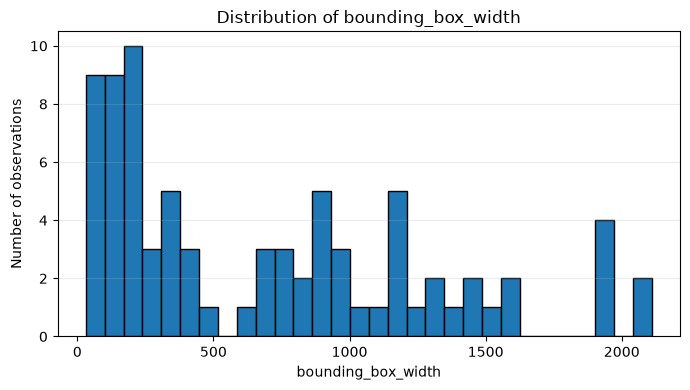

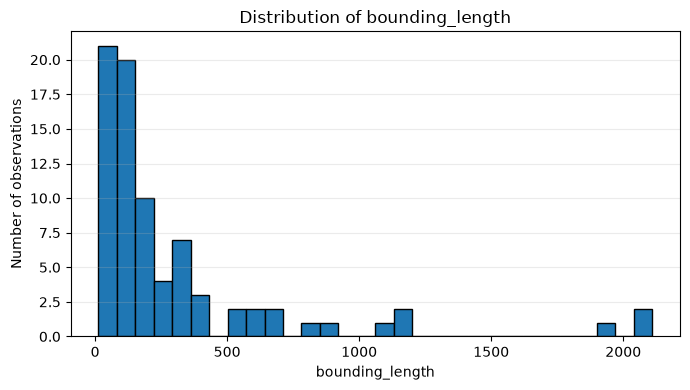

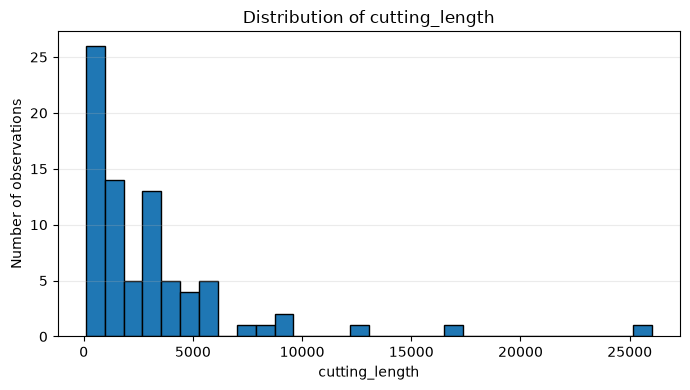

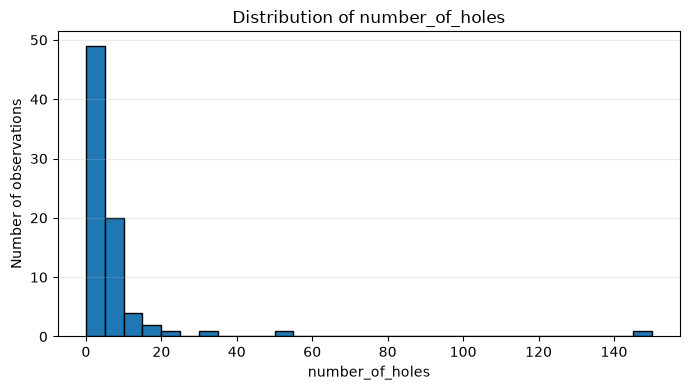

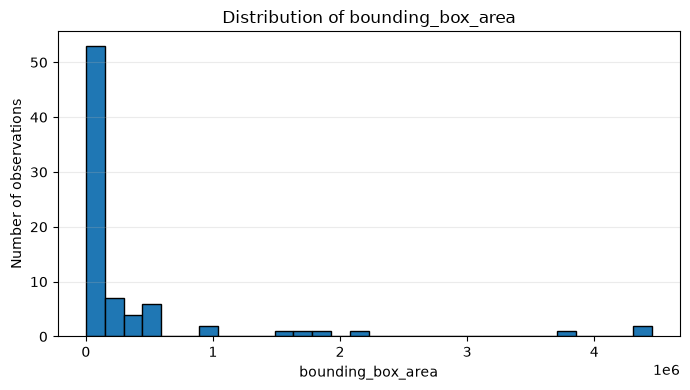

In [22]:
for feature in available_features:
    values = numeric_df[feature].dropna()
    if values.empty:
        continue
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(values, bins=30, edgecolor="black")
    ax.set(title=f"Distribution of {feature}", xlabel=feature, ylabel="Number of observations")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

All the attributes show a positive skew, and there appears a trend of leptokurtosis, meaning the data is "very peaked" in comparison to the lowest attribute values in the positive direction.

### Boxplots and unusual observations

A boxplot summarizes the median and quartiles and highlights potential outliers.

The IQR rule flags values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

**An outlier is not automatically an error.** A very large or intricate part may be a genuine product.

C:\Users\trish\AppData\Local\Temp\ipykernel_12084\1766951068.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


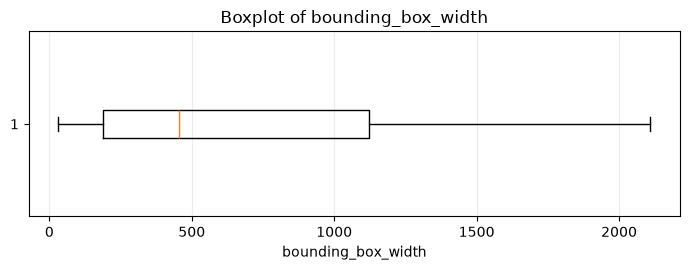

C:\Users\trish\AppData\Local\Temp\ipykernel_12084\1766951068.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


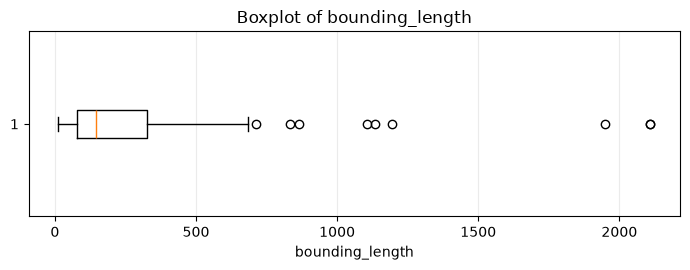

C:\Users\trish\AppData\Local\Temp\ipykernel_12084\1766951068.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


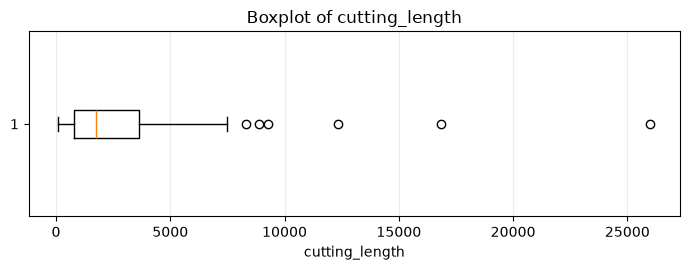

C:\Users\trish\AppData\Local\Temp\ipykernel_12084\1766951068.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


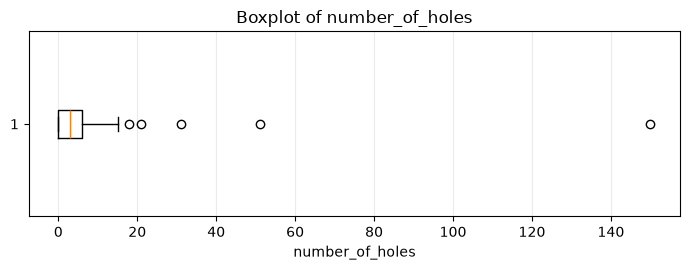

C:\Users\trish\AppData\Local\Temp\ipykernel_12084\1766951068.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


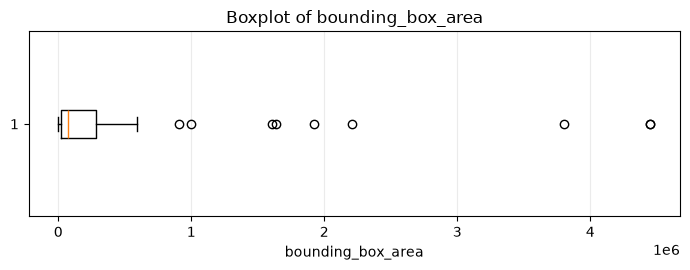

In [23]:
for feature in available_features:
    values = numeric_df[feature].dropna()
    if values.empty:
        continue
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.boxplot(values, vert=False)
    ax.set(title=f"Boxplot of {feature}", xlabel=feature)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

In the table below, the outliers are listed for each feature.We calculated the first and third quantile (Q1 and Q3) and the Inter-Quartile Range (IQR = Q3 - Q1) and define the lower and upper bounds for outliers as follows:
- Lower bound = Q1 - 1.5 * IQR
- Upper bound = Q3 + 1.5 * IQR   

The observations that fall outside are considered outliers. In the context of laser cutting, these outliers may represent parts that are unusually large or complex, which could be of interest for further inspection. It is important to note that not all outliers are errors. Therefore is important to continue analyzing these outliers in the following steps.

In [24]:
outlier_rows = []

for feature in available_features:
    values = numeric_df[feature].dropna()
    if values.empty:
        continue

    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = numeric_df[feature].notna() & (
        (numeric_df[feature] < lower) | (numeric_df[feature] > upper)
    )

    for idx in df.index[mask]:
        row = {
            "row_index": idx,
            "feature": feature,
            "value": df.loc[idx, feature],
            "lower_bound": lower,
            "upper_bound": upper,
        }
        for id_col in ID_COLUMNS:
            if id_col in df.columns:
                row[id_col] = df.loc[idx, id_col]
        outlier_rows.append(row)

outliers = pd.DataFrame(outlier_rows)

if outliers.empty:
    print("No IQR outliers detected.")
else:
    display(
        outliers.sort_values(["feature", "value"], ascending=[True, False])
        .style.format(
            {"value": "{:,.2f}", "lower_bound": "{:,.2f}", "upper_bound": "{:,.2f}"}
        )
    )

,row_index,feature,value,lower_bound,upper_bound
20,0,bounding_box_area,"4,452,100.26","-376,149.86","681,118.92"
22,25,bounding_box_area,"4,452,100.00","-376,149.86","681,118.92"
21,16,bounding_box_area,"3,802,500.07","-376,149.86","681,118.92"
23,29,bounding_box_area,"2,209,629.28","-376,149.86","681,118.92"
25,48,bounding_box_area,"1,921,278.69","-376,149.86","681,118.92"
28,77,bounding_box_area,"1,638,981.75","-376,149.86","681,118.92"
26,51,bounding_box_area,"1,606,399.07","-376,149.86","681,118.92"
24,31,bounding_box_area,"996,411.32","-376,149.86","681,118.92"
27,65,bounding_box_area,"905,771.34","-376,149.86","681,118.92"
0,0,bounding_length,"2,110.00",-294.99,698.72


## 3 & 4. Bivariate and Multivariate Analysis, with Outlier Detection

### Corelation matrix with outliers

Pearson correlation measures the strength and direction of **linear** relationships.

- Near `+1`: strong positive linear association.
- Near `-1`: strong negative linear association.
- Near `0`: weak linear association.

Correlation does not prove causation and can miss nonlinear relationships. Extreme observations can influence it.

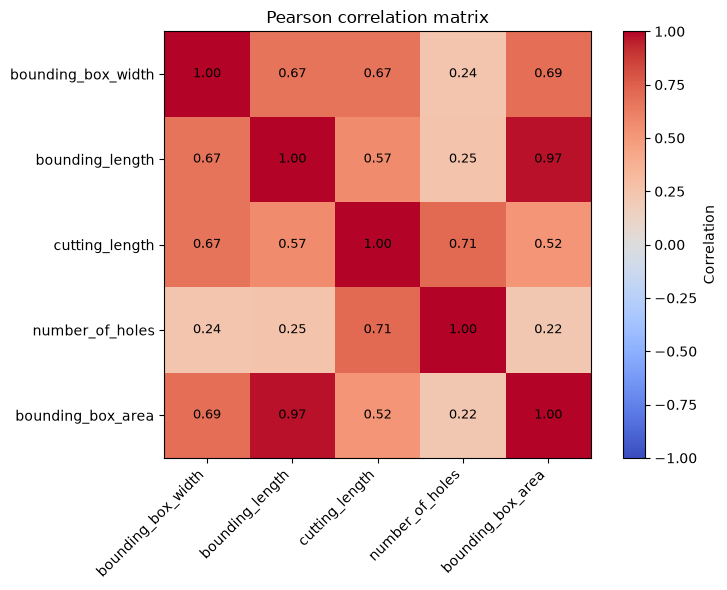

,bounding_box_width,bounding_length,cutting_length,number_of_holes,bounding_box_area
bounding_box_width,1.000,0.669,0.672,0.236,0.692
bounding_length,0.669,1.000,0.569,0.255,0.971
cutting_length,0.672,0.569,1.000,0.710,0.522
number_of_holes,0.236,0.255,0.710,1.000,0.221
bounding_box_area,0.692,0.971,0.522,0.221,1.000


In [25]:
correlation = numeric_df.corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.index)))
ax.set_xticklabels(correlation.columns, rotation=45, ha="right")
ax.set_yticklabels(correlation.index)
ax.set_title("Pearson correlation matrix")

for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        value = correlation.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()
display(correlation.round(3))

### Correlation matrix without outliers



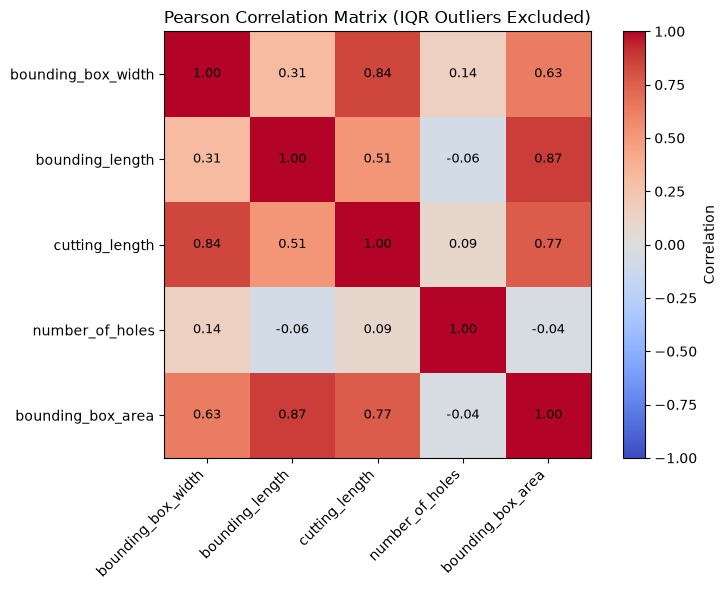

,bounding_box_width,bounding_length,cutting_length,number_of_holes,bounding_box_area
bounding_box_width,1.000,0.307,0.839,0.141,0.629
bounding_length,0.307,1.000,0.513,-0.064,0.874
cutting_length,0.839,0.513,1.000,0.087,0.765
number_of_holes,0.141,-0.064,0.087,1.000,-0.042
bounding_box_area,0.629,0.874,0.765,-0.042,1.000


Excluded 12 rows; 67 rows remain.


In [26]:
outlier_indices = outliers["row_index"].unique() if not outliers.empty else []
numeric_inliers = numeric_df.loc[~numeric_df.index.isin(outlier_indices)]

correlation_without_outliers = numeric_inliers.corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlation_without_outliers, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(correlation_without_outliers.columns)))
ax.set_yticks(range(len(correlation_without_outliers.index)))
ax.set_xticklabels(correlation_without_outliers.columns, rotation=45, ha="right")
ax.set_yticklabels(correlation_without_outliers.index)
ax.set_title("Pearson Correlation Matrix (IQR Outliers Excluded)")

for i in range(len(correlation_without_outliers.index)):
    for j in range(len(correlation_without_outliers.columns)):
        value = correlation_without_outliers.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

display(correlation_without_outliers.round(3))
print(f"Excluded {len(outlier_indices)} rows; {len(numeric_inliers)} rows remain.")

This correlation matrixs will be used in future steps in order to explore the relationship between the attributes, taking in account with outliers and without outliers.

### Scatterplots with outliers

In this scatterplot is possible to appreciate if there is any relationship between two features:

- In the first scatterplot, is possible to see that there is no relationship between the cutting legth and the bounding box area, since there is no a clear view of a pattern on the data.
- On the second scatterplot, there no relationship between the number of holes and cutting length, but is possible to appreciate a big concentration of the datain the records of zero holes.
- on the third scatterplot, a linear relationship between the bounding width and bounding length is appreciated. 

,customer_name,customer_branch,file_name,order_quantity,possible_duplicate,bounding_box_width,bounding_length,cutting_length,number_of_holes,bounding_box_area
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,False,2110.000062,2110.000062,3438.024977,0.0,4.452100e+06
16,MetalForm SA,Frankfurt Branch,Geo (25).DXF,1100,False,1950.000009,1950.000029,12326.862958,5.0,3.802500e+06
25,MetalForm SA,Frankfurt Branch,Geo (33).DXF,850,False,2110.000000,2110.000000,3625.275477,3.0,4.452100e+06
29,MetalForm SA,Frankfurt Branch,Geo (37).DXF,1800,False,1947.204525,1134.770001,8330.442132,31.0,2.209629e+06
31,MetalForm SA,Frankfurt Branch,Geo (39).DXF,1250,False,1400.631661,711.401400,6059.394370,18.0,9.964113e+05
39,AutoParts AG,Berlin Branch,Geo (47).DXF,7900,False,900.572159,90.963841,2776.804983,21.0,8.191950e+04
48,MetalForm SA,Frankfurt Branch,Geo (54).DXF,1050,False,1610.107161,1193.261380,26007.870470,150.0,1.921279e+06
51,MetalForm SA,Frankfurt Branch,Geo (57).DXF,500,False,1453.993892,1104.818309,9286.051115,6.0,1.606399e+06
59,AutoParts AG,Munich Branch,Geo (64).DXF,8650,False,899.317895,628.570597,8862.895041,8.0,5.652848e+05
65,MetalForm SA,Frankfurt Branch,Geo (69).DXF,1100,False,1047.443056,864.745182,3847.894165,0.0,9.057713e+05


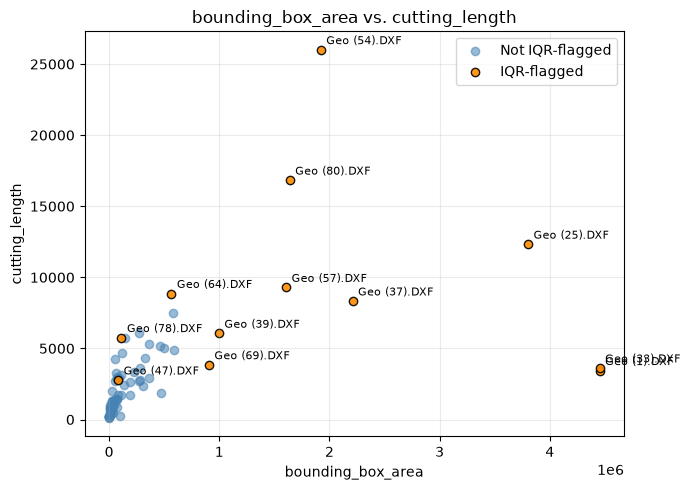

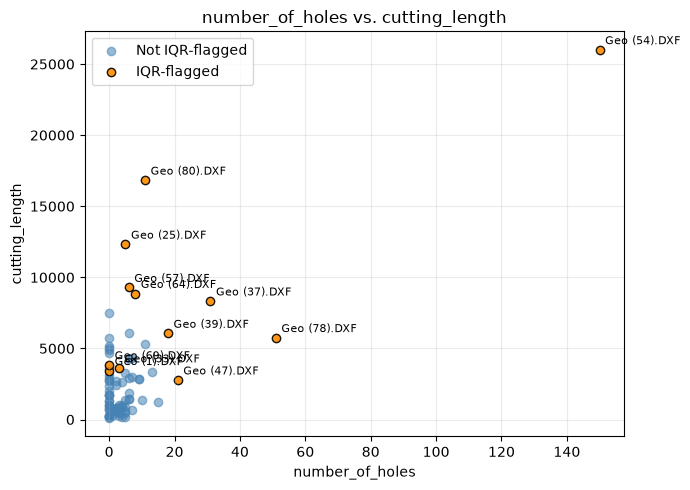

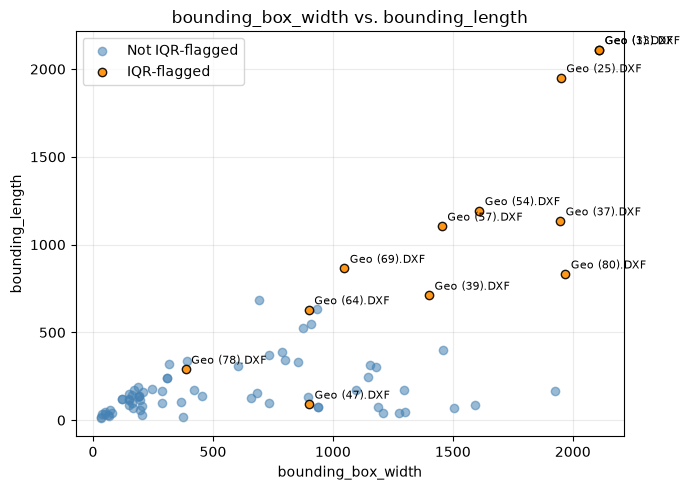

In [27]:
# Show all available columns for rows flagged in the previous outlier list
outlier_indices_for_review = sorted(outliers["row_index"].unique())

if outlier_indices_for_review:
    display(df.loc[outlier_indices_for_review].sort_index())
else:
    print("No IQR-flagged rows to review.")

# Plot selected feature relationships, highlighting any IQR-flagged rows
flagged_mask = df.index.isin(outlier_indices_for_review)
review_pairs = [
    ("bounding_box_area", "cutting_length"),
    ("number_of_holes", "cutting_length"),
    ("bounding_box_width", "bounding_length"),
]

label_column = next(
    (col for col in ["file_name", "filename"] if col in df.columns),
    None
)

for x_col, y_col in review_pairs:
    if x_col not in df.columns or y_col not in df.columns:
        print(f"Skipping {x_col} vs. {y_col}: column missing.")
        continue

    plot_data = df[[x_col, y_col]].apply(pd.to_numeric, errors="coerce")
    valid = plot_data.notna().all(axis=1)
    regular = valid & ~flagged_mask
    flagged = valid & flagged_mask

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        plot_data.loc[regular, x_col], plot_data.loc[regular, y_col],
        alpha=0.55, color="steelblue", label="Not IQR-flagged"
    )
    ax.scatter(
        plot_data.loc[flagged, x_col], plot_data.loc[flagged, y_col],
        alpha=0.9, color="darkorange", edgecolor="black",
        label="IQR-flagged"
    )

    if label_column:
        for row_idx in plot_data.index[flagged]:
            ax.annotate(
                str(df.loc[row_idx, label_column]),
                (plot_data.loc[row_idx, x_col], plot_data.loc[row_idx, y_col]),
                xytext=(4, 4), textcoords="offset points", fontsize=8
            )

    ax.set(title=f"{x_col} vs. {y_col}", xlabel=x_col, ylabel=y_col)
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

## Dealing with High-dimensional Data
### Analysis and exploration of findings

### Observation 1 number of holes and cutting length.

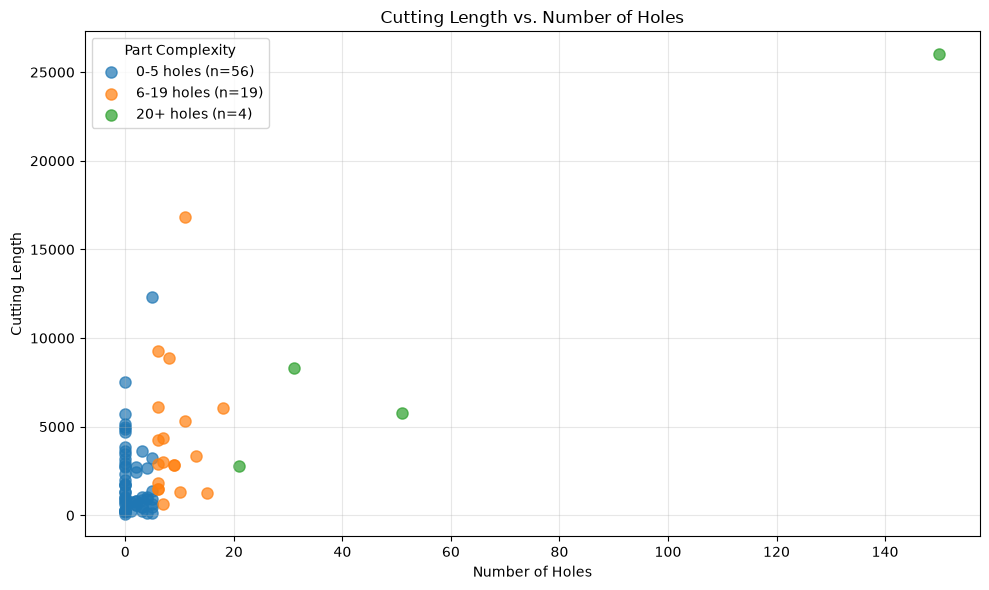

In [28]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Prepare data
# --------------------------------------------------

plot_df = df[["number_of_holes", "cutting_length"]].copy()

plot_df["number_of_holes"] = pd.to_numeric(
    plot_df["number_of_holes"], errors="coerce"
)

plot_df["cutting_length"] = pd.to_numeric(
    plot_df["cutting_length"], errors="coerce"
)

plot_df = plot_df.dropna()

# --------------------------------------------------
# 2. Create groups
# --------------------------------------------------

plot_df["hole_group"] = np.select(
    [
        plot_df["number_of_holes"].between(0, 5),
        plot_df["number_of_holes"].between(6, 19),
        plot_df["number_of_holes"] >= 20
    ],
    [
        "0-5 holes",
        "6-19 holes",
        "20+ holes"
    ],
    default="Other"
)

# --------------------------------------------------
# 3. Scatterplot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

groups = ["0-5 holes", "6-19 holes", "20+ holes"]

for group in groups:
    subset = plot_df[plot_df["hole_group"] == group]

    ax.scatter(
        subset["number_of_holes"],
        subset["cutting_length"],
        label=f"{group} (n={len(subset)})",
        alpha=0.7,
        s=65
    )

ax.set_title("Cutting Length vs. Number of Holes")
ax.set_xlabel("Number of Holes")
ax.set_ylabel("Cutting Length")
ax.legend(title="Part Complexity")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



In [29]:

# Mean cutting length by number of holes

plot_df["hole_group"] = np.select(
    [
        plot_df["number_of_holes"].between(0, 5),
        plot_df["number_of_holes"].between(6, 19),
        plot_df["number_of_holes"] >= 20
    ],
    ["0-5 holes", "6-19 holes", "20+ holes"],
    default="Other"
)

mean_by_group = (
    plot_df.groupby("hole_group")["cutting_length"]
    .agg(["count", "mean", "median"])
    .reindex(["0-5 holes", "6-19 holes", "20+ holes"])
)

print(mean_by_group.round(2))


            count      mean   median
hole_group                          
0-5 holes      56   2010.95  1045.41
6-19 holes     19   4421.71  3011.77
20+ holes       4  10718.17  7043.99




Cutting length and Number of holes show a significant correlation of 0.71, as can be observed on the scatter plot. 

* Between 0-5 holes, the mean cutting length is 2000.95mm, i.e., most parts have short cutting lengths. Note that 56 of the 74 observations include <=5 holes, and most of these observations are concentrated between 0 and 4000mm. 

* Between 6-19 holes, cutting length increases significantly with a mean cutting length of 4421.7mm. Note that in this category, there are only 19 observations, and their length vary more.

* For >20 holes, the mean cutting length is 10718.17 mm. However, here, we only have 4 observations and they have significant variations. 

Therefore, there is a clear pattern of increasing Cutting length with Number of holes. However, if we remove outliers, the category >20 becomes obsolete, and the pearson correlation drops to 0.09. This is especially important because the intial correlation value is heavily influenced by Geo(54).DXF which has a staggering 150 holes, where the median number of holes is 3.

### Finding 2: Cutting legnth and bounding box area.


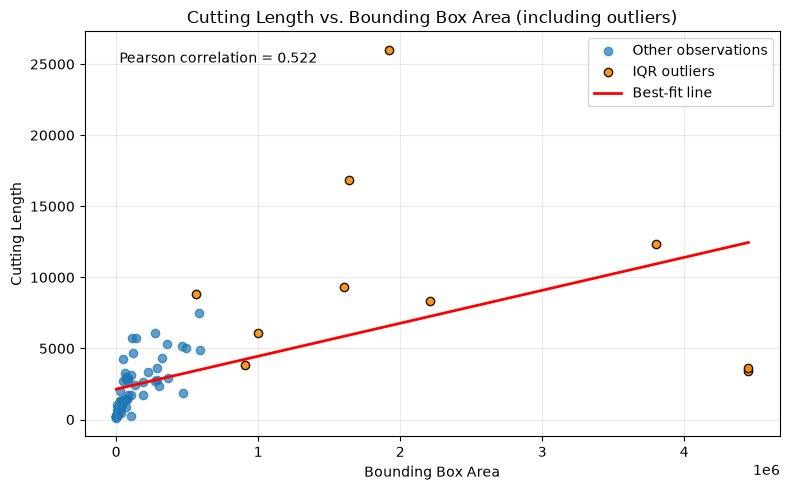

Pearson correlation coefficient (all observations): 0.522


In [30]:
# Plot all observations, including IQR outliers
x_col, y_col = "bounding_box_area", "cutting_length"
plot_data = numeric_df[[x_col, y_col]].dropna()

# Flag observations outside the IQR bounds for either feature
outlier_mask = pd.Series(False, index=plot_data.index)
for col in [x_col, y_col]:
    q1, q3 = plot_data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask |= ~plot_data[col].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

x, y = plot_data[x_col], plot_data[y_col]
pearson_r = x.corr(y)

slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x[~outlier_mask], y[~outlier_mask], alpha=0.7, label="Other observations")
ax.scatter(
    x[outlier_mask], y[outlier_mask],
    color="darkorange", edgecolor="black", alpha=0.9,
    label="IQR outliers"
)
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=2, label="Best-fit line")

ax.set(
    title="Cutting Length vs. Bounding Box Area (including outliers)",
    xlabel="Bounding Box Area",
    ylabel="Cutting Length",
)
ax.text(0.05, 0.95, f"Pearson correlation = {pearson_r:.3f}",
        transform=ax.transAxes, va="top")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Pearson correlation coefficient (all observations): {pearson_r:.3f}")

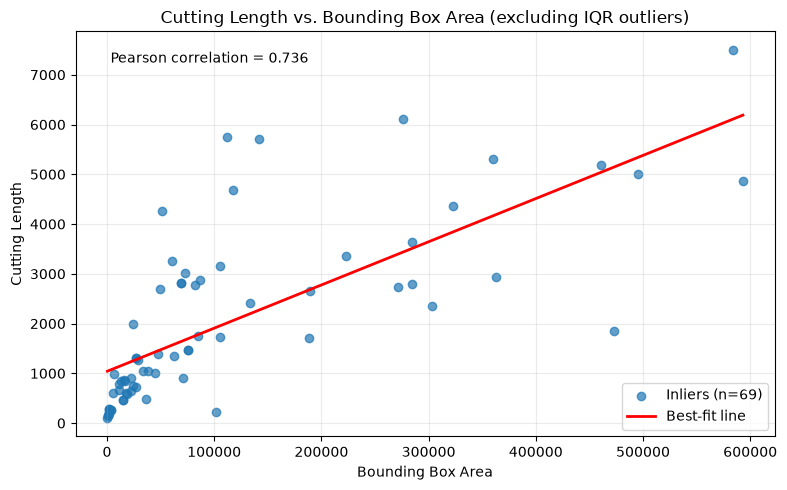

Pearson correlation coefficient (inliers): 0.736


In [31]:
x_col, y_col = "bounding_box_area", "cutting_length"
scatter_df = numeric_df[[x_col, y_col]].dropna().copy()

inliers = pd.Series(True, index=scatter_df.index)
for feature in [x_col, y_col]:
    q1 = scatter_df[feature].quantile(0.25)
    q3 = scatter_df[feature].quantile(0.75)
    iqr = q3 - q1
    inliers &= scatter_df[feature].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)


fit_data = scatter_df.loc[inliers]
x = fit_data["bounding_box_area"]
y = fit_data["cutting_length"]

if len(fit_data) < 2:
    raise ValueError("At least two inlier observations are needed to fit a line.")

slope, intercept = np.polyfit(x, y, 1)
correlation_coefficient = x.corr(y)

x_line = np.linspace(x.min(), x.max(), 200)
y_line = slope * x_line + intercept

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.7, label=f"Inliers (n={len(fit_data)})")
ax.plot(x_line, y_line, color="red", linewidth=2, label="Best-fit line")

ax.set(
    title="Cutting Length vs. Bounding Box Area (excluding IQR outliers)",
    xlabel="Bounding Box Area",
    ylabel="Cutting Length",
)
ax.text(
    0.05, 0.95,
    f"Pearson correlation = {correlation_coefficient:.3f}",
    transform=ax.transAxes,
    va="top",
)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Pearson correlation coefficient (inliers): {correlation_coefficient:.3f}")

The pearson correlation of cutting length with bounding box area is 0.522. However, this correlation increases very significantly, when we calculate without the outliers, giving us a value of 0.736. Therefore, there is a strong correlation between Bounding box area and Cutting length.

### Finding 3 - Number of holes interaction with Bounding box area and Cutting length.

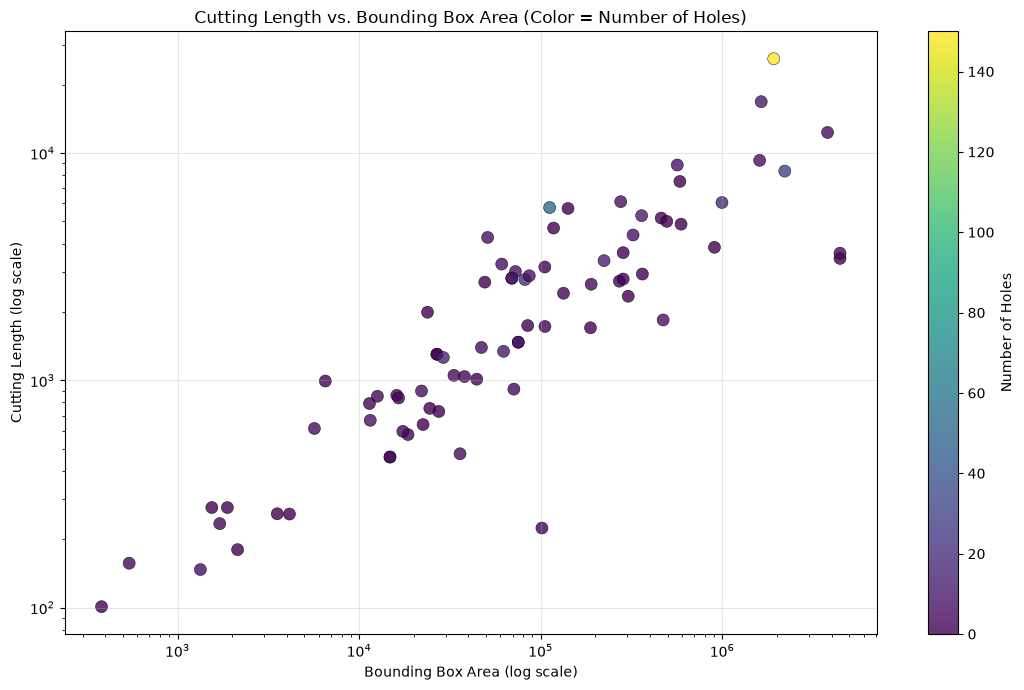

In [32]:

import pandas as pd
import matplotlib.pyplot as plt

# Prepare data
analysis_df = df[
    ["bounding_box_area", "cutting_length", "number_of_holes"]
].copy()

for col in analysis_df.columns:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col], errors="coerce"
    )

analysis_df = analysis_df.dropna()

# Remove invalid values for logarithmic visualization
analysis_df = analysis_df[
    (analysis_df["bounding_box_area"] > 0) &
    (analysis_df["cutting_length"] > 0) &
    (analysis_df["number_of_holes"] >= 0)
]

# Scatterplot
fig, ax = plt.subplots(figsize=(11, 7))

scatter = ax.scatter(
    analysis_df["bounding_box_area"],
    analysis_df["cutting_length"],
    c=analysis_df["number_of_holes"],
    cmap="viridis",
    s=75,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.4
)

ax.set_xscale("log")
ax.set_yscale("log")

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Number of Holes")

ax.set_title(
    "Cutting Length vs. Bounding Box Area"
    " (Color = Number of Holes)"
)
ax.set_xlabel("Bounding Box Area (log scale)")
ax.set_ylabel("Cutting Length (log scale)")

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


As we can see on the scatter plot, Bounding box area and  number of holes have a very clear linear relationship. However, as signified by the colored points, cutting length does not vary very much with number of holes. Therefore, the affect of number of holes on cutting length and thus, cutting time and retrieval effort, is mostly negligible. However, the majority of the data provided includes parts with either no holes or less than 5 holes. So, we do not have enough data to draw conclusions about how number of holes affect cutting length.

# Limitations:

1) Size of Data sample: With only 80 samples, it is impossible to draw strong conclusions and carry out predictive analyses necessary for meaningful interpretations.

2) Not enough Attributes: We aren't provided the cutting speed, or any information on the retrieval process. Therefore, we can only make highly speculative analysis on part retrieval effort and cutting time. No information about storage organization, part weight, labeling or actual retrieval times is provided. Therefore, retrieval effort cannot be directly quantified using the available features.

3) Positive Skew and Observed Leptokurtosis: The positive skew and leptokurtosis can affect the quality of the data interpretation.

# Conclusion

We can see that when bounding box area increases, cutting length also increases. We can therefore reasonable extrapolate that cutting time and retrieval effort will be higher. There appears to be a slight correlation between cutting length and number of holes, and logically, one can conclude that cutting time will be higher, and cutting process will be more, increasing retrieval time as well. However, this is not sufficiently backed with the data available. Removing outliers reduces the pearson correlation of number of holes and cutting length to only 0.09. Finally, we want to draw attention to the fact that the data has a positive skew and is leptokurtic, which could be affecting our results.   